In [3]:
import pandas as pd

In [9]:
df = pd.read_csv("insurance.csv").dropna()

In [5]:
num_observations = len(df)
df.duplicated().sum()

duplicates = df[df.duplicated(keep=False)]
no_duplicates = df.drop_duplicates()
no_duplicates


,age,sex,bmi,children,smoker,region,charges;;
0,19,female,27.900,0,yes,southwest,16884.924;;
1,18,male,33.770,1,no,southeast,1725.5523;;
2,28,male,33.000,3,no,southeast,4449.462;;
3,33,male,22.705,0,no,northwest,21984.47061;;
4,32,male,28.880,0,no,northwest,3866.8552;;
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.5483;;
1334,18,female,31.920,0,no,northeast,2205.9808;;
1335,18,female,36.850,0,no,southeast,1629.8335;;
1336,21,female,25.800,0,no,southwest,2007.945;;


In [6]:
num_of_nans = df[df.isna().any(axis=1)]
num_of_nans

,age,sex,bmi,children,smoker,region,charges;;


In [7]:
df["charges;;"] = df["charges;;"].str.replace(";","").astype(float)

In [8]:
no_nans_df = df["charges;;"].fillna(df["charges;;"].mean())
no_nans_df.head(10), df.head(10)

(0     16884.92400
 1      1725.55230
 2      4449.46200
 3     21984.47061
 4      3866.85520
 6      8240.58960
 7      7281.50560
 8      6406.41070
 9     28923.13692
 10     2721.32080
 Name: charges;;, dtype: float64,
     age     sex     bmi  children smoker     region    charges;;
 0    19  female  27.900         0    yes  southwest  16884.92400
 1    18    male  33.770         1     no  southeast   1725.55230
 2    28    male  33.000         3     no  southeast   4449.46200
 3    33    male  22.705         0     no  northwest  21984.47061
 4    32    male  28.880         0     no  northwest   3866.85520
 6    46  female  33.440         1     no  southeast   8240.58960
 7    37  female  27.740         3     no  northwest   7281.50560
 8    37    male  29.830         2     no  northeast   6406.41070
 9    60  female  25.840         0     no  northwest  28923.13692
 10   25    male  26.220         0     no  northeast   2721.32080)

In [9]:
mean_charges = df["charges;;"].mean()
median_charges = df["charges;;"].median()
max_value = df["charges;;"].max()
min_value = df["charges;;"].min()
print(f"Mean charges:   {max_value:.2f}")

Mean charges:   63770.43


(array([1.04091576e-04, 7.88572545e-05, 7.72801095e-05, 6.86058115e-05,
        7.01829565e-05, 6.62400938e-05, 6.70286664e-05, 5.91429409e-05,
        6.70286664e-05, 5.52000782e-05, 3.70629096e-05, 1.89257411e-05,
        5.52000782e-06, 2.36571764e-06, 7.88572545e-06, 5.52000782e-06,
        7.09715291e-06, 4.73143527e-06, 3.94286273e-06, 5.52000782e-06,
        5.52000782e-06, 5.52000782e-06, 5.52000782e-06, 1.57714509e-06,
        3.15429018e-06, 1.57714509e-06, 0.00000000e+00, 7.88572545e-07,
        7.88572545e-07, 1.57714509e-06]),
 array([ 1121.8739    ,  2314.83170433,  3507.78950867,  4700.747313  ,
         5893.70511733,  7086.66292167,  8279.620726  ,  9472.57853033,
        10665.53633467, 11858.494139  , 13051.45194333, 14244.40974767,
        15437.367552  , 16630.32535633, 17823.28316067, 19016.240965  ,
        20209.19876933, 21402.15657367, 22595.114378  , 23788.07218233,
        24981.02998667, 26173.987791  , 27366.94559533, 28559.90339967,
        29752.861204  

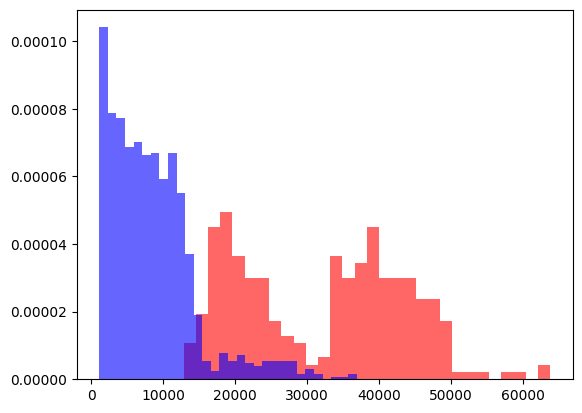

In [10]:
import matplotlib.pyplot as plt

smoker = df[df["smoker"]=="yes"]["charges;;"].dropna().tolist()
not_smoker = df[df["smoker"]== "no"]["charges;;"].dropna().tolist()

plt.hist(smoker, bins = 30,density = True, alpha = 0.6,label="smoker", color="red")
plt.hist(not_smoker, bins=30, density=True, alpha = 0.6, label="not_smoker", color="blue")

<Axes: xlabel='charges;;', ylabel='Count'>

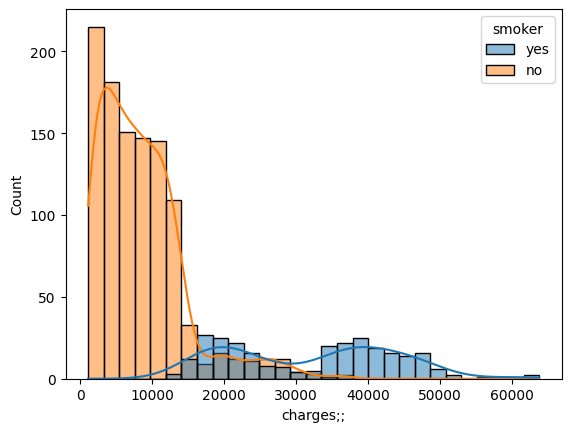

In [11]:
import seaborn as sns


sns.histplot(data=df, x="charges;;", hue="smoker", kde=True,stat="count",common_norm=False)

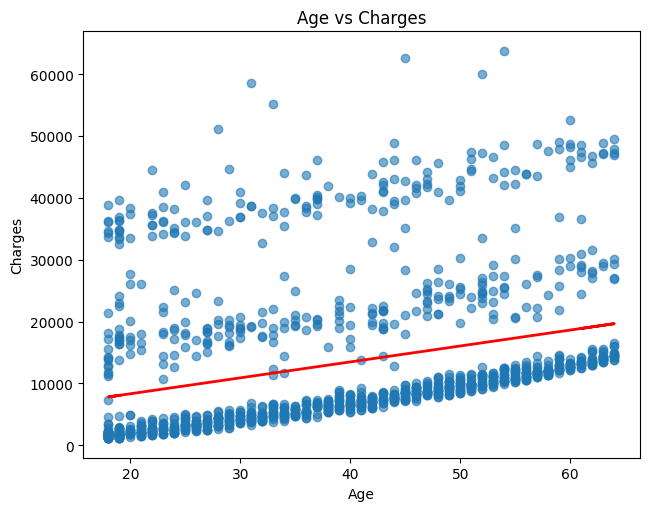

In [12]:
# scatter plot
import numpy as np

x = df["age"]
y = df["charges;;"]

plt.scatter(x,y, alpha=0.6)
w, b = np.polyfit(x, y,1)

plt.plot(x, w*x+b, color ="red", linewidth=2)


plt.tight_layout()
plt.xlabel("Age")
plt.ylabel("Charges")
plt.title("Age vs Charges")
plt.show()



<Axes: xlabel='charges;;', ylabel='Count'>

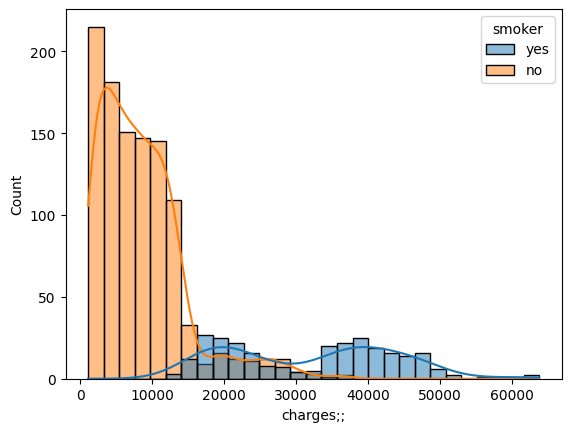

In [13]:
import seaborn as sns
sns.histplot(data=df, x="charges;;", hue="smoker", kde=True,stat="count",common_norm=False)

In [40]:
df.groupby("smoker")["charges;;"].agg(["mean", "median", "max"])

,mean,median,max
smoker,,,
no,8438.668718,7345.72660,36910.60803
yes,32050.231832,34456.34845,63770.42801


In [ ]:
binary_values = {"yes": 1, "no": 0}

df["smoker_num"] = df["smoker"].map(binary_values)

0       1
1       0
2       0
3       0
4       0
       ..
1333    0
1334    0
1335    0
1336    0
1337    1
Name: smoker_num, Length: 1337, dtype: int64

In [57]:
correl = df["smoker_num"].corr(df["charges;;"])
correl

np.float64(0.7872107887429449)

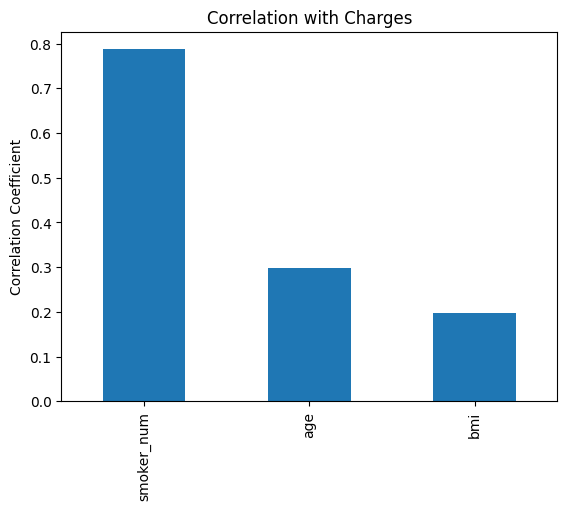

In [62]:
correl = df[["smoker_num", "age", "bmi"]].corrwith(df["charges;;"])
correl.plot(kind="bar")
plt.ylabel("Correlation Coefficient")
plt.title("Correlation with Charges")
plt.show()

<Axes: xlabel='smoker'>

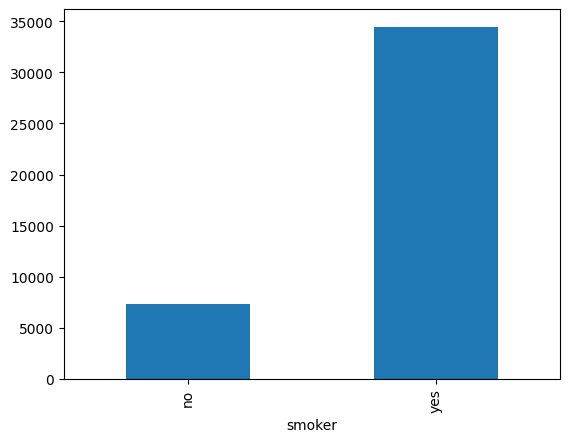

In [ ]:
avg_smoker = df.groupby("smoker")["charges;;"].mean()
median_smoker = df.groupby("smoker")["charges;;"].median()
avg_smoker.plot(kind="bar")
median_smoker.plot(kind="bar")

In [72]:
corr_smokers_bmi = df.groupby("smoker")["charges;;"].corr(df["bmi"])
corr_smokers_bmi

smoker
no     0.083489
yes    0.806481
Name: charges;;, dtype: float64

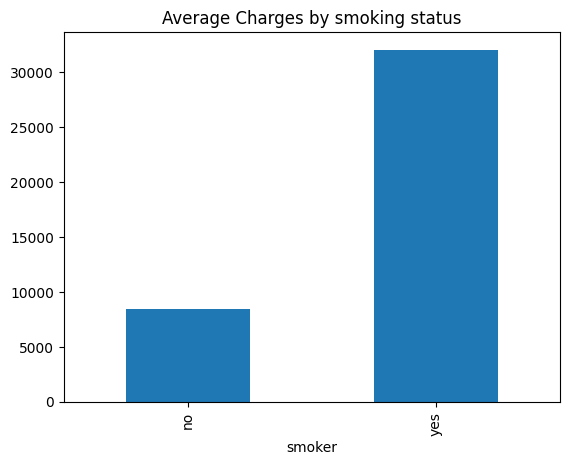

In [31]:
df.groupby("smoker")["charges;;"].mean().plot(kind="bar", title="Average Charges by smoking status")
plt.show()

- Median: The middle observation after sorting. It is relatively unaffected by extreme values.
- Mean: The sum of all observations divided by their number. The €9,000 observation pulls it upward considerably.
Therefore, when mean > median, this often suggests a right-skewed distribution: most observations are relatively low, but a few very high values pull the average upward.



If you wanted to describe the medical expenses of a typical customer, would you report the mean or the median? And why?

Median (€300): Better represents the typical customer's medical expenses because it is less affected by extreme values.
Mean (€2,000): Better reflects the average financial cost per customer, which is important for insurers when estimating total expenditure.



In [73]:
df = df.rename(columns={"charges;;": "charges"})

summary = df.groupby("smoker")["charges"].agg(["std","count","mean", "median"])
summary

,std,count,mean,median
smoker,,,,
no,5994.883335,1063,8438.668718,7345.72660
yes,11541.547176,274,32050.231832,34456.34845


<Axes: xlabel='smoker', ylabel='charges'>

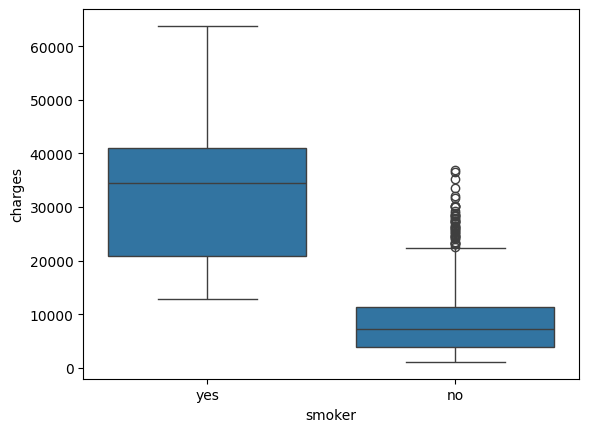

In [74]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df, x="smoker", y="charges")

In [ ]:
smokers = df[df["smoker"] == "yes"]
smokers["charges"]

0       16884.92400
11      27808.72510
14      39611.75770
19      36837.46700
23      37701.87680
           ...     
1313    36397.57600
1314    18765.87545
1321    28101.33305
1323    43896.37630
1337    29141.36030
Name: charges, Length: 274, dtype: float64

### Part 2


In [80]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df_train = pd.read_csv("train.csv", encoding="utf-8")

In [113]:
df_train

,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival
...,...,...
9998,You provide support in what countries?,country_support
9999,What countries are you supporting?,country_support
10000,What countries are getting support?,country_support
10001,Are cards available in the EU?,country_support


In [127]:
unique_intents= (df_train["category"].nunique())

In [125]:
count_intents = df_train["category"].value_counts()

In [128]:
print(f"Number of NANs:{df_train.isna().sum()}")
print(f"Number of duplicates: {df_train.duplicated().sum()}")
print(f"Number of unique intents: {unique_intents}")

Number of NANs:text        0
category    0
dtype: int64
Number of duplicates: 0
Number of unique intents: 77


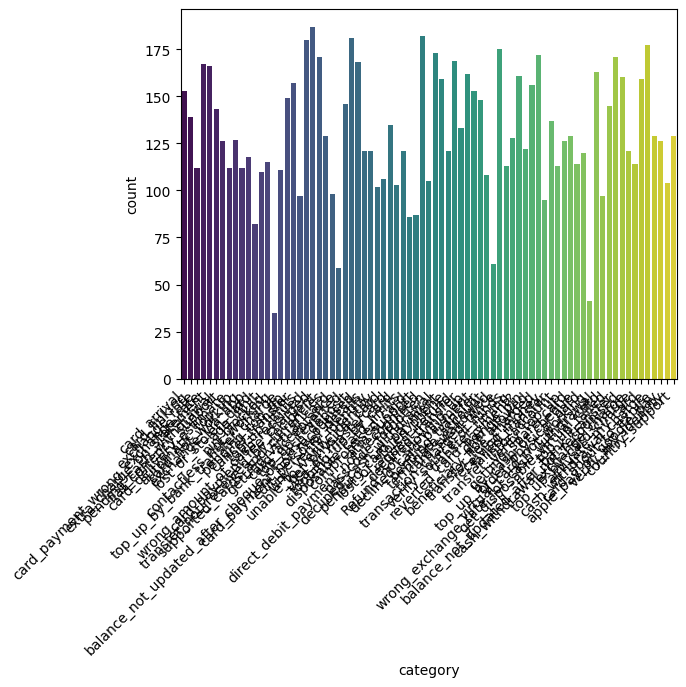

In [ ]:
sns.countplot(data=df_train, x="category", hue="category", palette="viridis")
plt.xticks(rotation=45, ha="right")  # Rotates labels so they don't overlap
plt.show()

# Notice that sns.barplot() accepts numerical values directly, whereas sns.countplot() counts observations automatically.

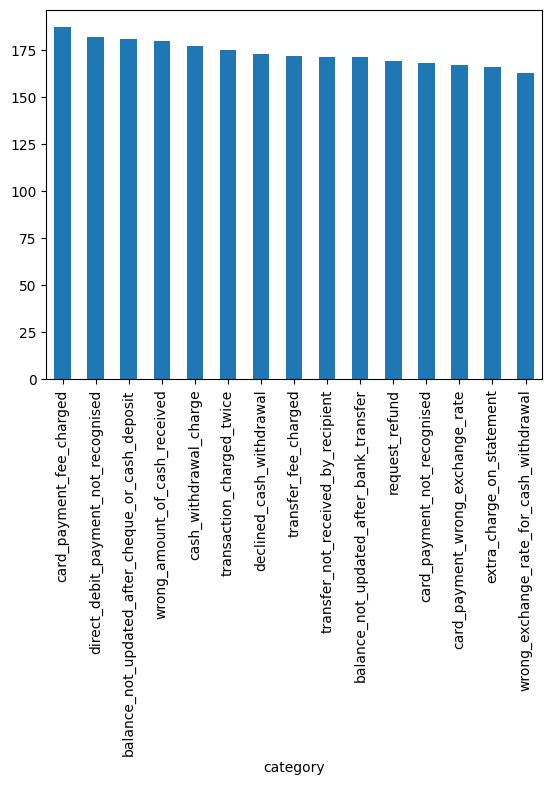

In [ ]:
# count_intents = df_train["category"].value_counts().head(15).plot(kind="bar")


# alternative:

top_15 = df_train["category"].value_counts().head(15)
# sns.barplot(x=top_15.values, y=top_15.index)

In [134]:
counts = df_train["category"].value_counts()
counts.min(), counts.max(), counts.mean()

(np.int64(35), np.int64(187), np.float64(129.9090909090909))

<Axes: xlabel='word_count', ylabel='Count'>

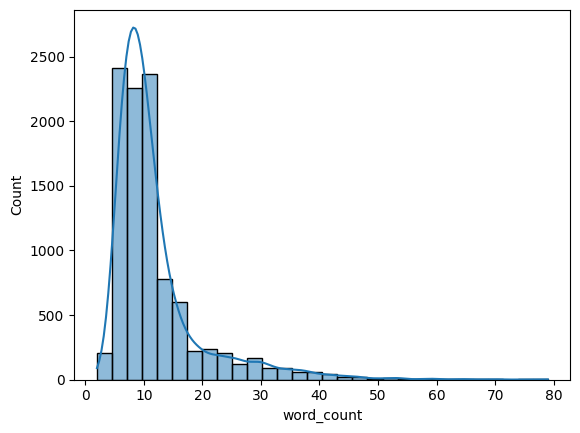

In [141]:
df_train["word_count"] = df_train["text"].str.split().str.len()
sns.histplot(data=df_train, x="word_count", bins=30, kde=True)

Important: A similar mean and median does not prove normality. A normal distribution is approximately symmetric and bell-shaped. You need to examine its overall shape.

2. Do longer messages improve NLP classification?
Not necessarily. Your intuition about context is correct, but length alone doesn't guarantee useful information.

Consider:
- Short: "My card was stolen." → Very clear intent.
- Long: "I was wondering whether you could perhaps help me with something related to my account..." → Longer, but potentially less informative.
Longer messages may contain more contextual clues, but also irrelevant information, ambiguity, or multiple intents.

In [144]:

df_train["word_count"].skew()

np.float64(2.613519235767973)

In [170]:
top_5 = df_train["category"].value_counts().head(5).index




messages = df_train[df_train["category"].isin(top_5)]
messages.groupby("category")["word_count"].describe()
# sns.boxplot(data= messages, x="category", y="word_count")


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
balance_not_updated_after_cheque_or_cash_deposit,181.0,14.237569,6.354694,5.0,10.0,13.0,17.00,41.0
card_payment_fee_charged,187.0,13.962567,6.964093,5.0,10.0,12.0,15.00,41.0
cash_withdrawal_charge,177.0,14.152542,8.586089,4.0,8.0,11.0,16.00,47.0
direct_debit_payment_not_recognised,182.0,15.989011,10.456428,3.0,10.0,12.0,16.75,58.0
wrong_amount_of_cash_received,180.0,15.283333,9.658571,4.0,9.0,12.0,18.00,53.0


In [172]:
messages.groupby("category")["word_count"].agg(["mean", "median", "min", "max"])

,mean,median,min,max
category,,,,
balance_not_updated_after_cheque_or_cash_deposit,14.237569,13.0,5,41
card_payment_fee_charged,13.962567,12.0,5,41
cash_withdrawal_charge,14.152542,11.0,4,47
direct_debit_payment_not_recognised,15.989011,12.0,3,58
wrong_amount_of_cash_received,15.283333,12.0,4,53


Why does this matter? When counting word frequencies, "card", "card!", and "card." should ideally count as the same word.

So:
- .split() separates text by whitespace.
- .findall(r"[a-z]+") extracts sequences of letters, excluding punctuation and numbers.

In [192]:
tokens = df_train["text"].str.lower().str.findall(r"[a-z]+")
tokens = tokens.explode() 
#transforms the lists into a single Series containing one word per row, making frequency counting straightforward.

In [193]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

tokens_no_stop_words = tokens[~tokens.isin(ENGLISH_STOP_WORDS)]
print(len(tokens))
print(len(tokens_no_stop_words))

122306
48433


In [184]:
print(tokens.head(20).tolist())
print(tokens.isin(ENGLISH_STOP_WORDS).sum())
print("the" in ENGLISH_STOP_WORDS)

['waiting', 'card', 'card', 'hasn', 't', 'arrived', 'weeks', 'waiting', 'week', 'card', 'coming', 'track', 'card', 'process', 'delivery', 'know', 'card', 'lost', 'did', 'send']
0
True


In [185]:
print(df_train["text"].head(5).tolist())

['I am still waiting on my card?', "What can I do if my card still hasn't arrived after 2 weeks?", 'I have been waiting over a week. Is the card still coming?', 'Can I track my card while it is in the process of delivery?', 'How do I know if I will get my card, or if it is lost?']


In [191]:
df_train = pd.read_csv("train.csv")

tokens = df_train["text"].str.lower().str.findall(r"[a-z]+").explode()

print("Before:", len(tokens))
print("Stopwords:", tokens.isin(ENGLISH_STOP_WORDS).sum())

tokens_clean = tokens[~tokens.isin(ENGLISH_STOP_WORDS)]
print("After:", len(tokens_clean))

Before: 122306
Stopwords: 73873
After: 48433


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [Text(0, 0, 'card'),
  Text(1, 0, 'account'),
  Text(2, 0, 'money'),
  Text(3, 0, 'transfer'),
  Text(4, 0, 'payment'),
  Text(5, 0, 'need'),
  Text(6, 0, 'cash'),
  Text(7, 0, 'exchange'),
  Text(8, 0, 'charged'),
  Text(9, 0, 'atm'),
  Text(10, 0, 'app'),
  Text(11, 0, 'fee'),
  Text(12, 0, 'use'),
  Text(13, 0, 'pending'),
  Text(14, 0, 'did'),
  Text(15, 0, 'help'),
  Text(16, 0, 'long'),
  Text(17, 0, 'transaction'),
  Text(18, 0, 'pin'),
  Text(19, 0, 'new')])

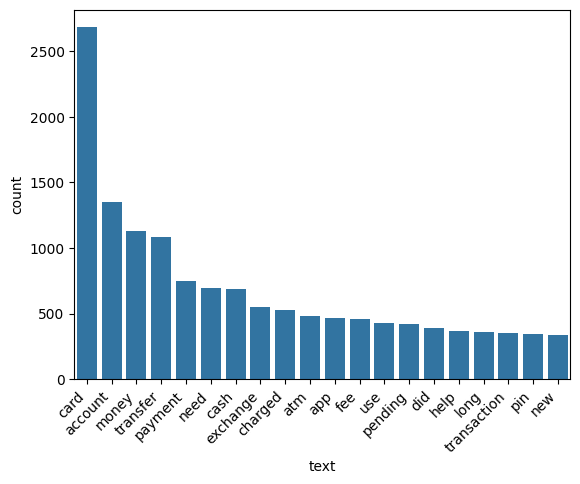

In [211]:
tokens_clean = tokens_clean[tokens_clean.str.len() >1]
top_20_tokens_clean = tokens_clean.value_counts().head(20)
sns.barplot(data=top_20_tokens_clean)
plt.xticks(rotation=45, ha="right")

### Regression Part

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

vectortizer = TfidfVectorizer(max_features=5000, stop_words="english")

X_train = vectortizer.fit_transform(df_train["text"])
X_test = vectortizer.transform(df_test["text"])
y_train = df_train["category"]
y_test = df_test["category"]


print(X_train.shape)

(10003, 2097)


In [ ]:

model = LogisticRegression(max_iter=1000)
# is a supervised machine learning algorithm, not a neural network 
# It learns weights connecting TF-IDF features to the 77 intent categories.
model.fit(X_train, y_train) #Trains the classifier using numerical features and correct labels.

preds = model.predict(X_test)
print(accuracy_score(y_test, preds))

0.8301948051948052


# Pytorch Loop

In [ ]:
import pandas as pd
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset


from sklearn.feature_extraction import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

texts_train, texts_val, labels_train, labels_val = train_test_split(
    df_train["text"],
    df_train["category"],
    random_state= 97,
    test_size=0.2
    stratify= df_train["category"])

vectorizer = TfidfVectorizer(max_features=5000, stop_words="english")

X_train = vectorizer.fit_transform(texts_train).toarray()
X_val = vectorizer.transform(texts_val).toarray()
X_test = vectorizer.transform(df_test["text"]).toarray()

encoder = LabelEncoder()

y_train = encoder.fit_transform(labels_train)
y_val = encoder.transform(labels_val)
y_test = encoder.transform(df_test["category"])

# Convert NumPy arrays into tensors
def make_loader(X, y, shuffle=False):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )
    return DataLoader(dataset, batch_size=64, shuffle=shuffle)

train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader = make_loader(X_val, y_val)
test_loader = make_loader(X_test, y_test)


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model = nn.Sequential(
    nn.Linear(X_train.shape[1], 128),
    nn.ReLU(),
    nn.Linear(128, len(encoder.classes_))
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [ ]:

epochs = 5

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # 1. Reset gradients
        optimizer.zero_grad()

        # 2. Forward pass
        predictions = model(X_batch)

        # 3. Calculate loss
        loss = criterion(predictions, y_batch)

        # 4. Backpropagation
        loss.backward()

        # 5. Update weights
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    avg_loss = total_loss / len(train_loader.dataset)

    print(f"Epoch {epoch+1}: Loss = {avg_loss:.4f}")


In [ ]:

from sklearn.metrics import accuracy_score, f1_score

def evaluate(model, loader):
    model.eval()
    predictions = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)

            logits = model(X_batch)
            predicted_classes = logits.argmax(dim=1)

            predictions.extend(predicted_classes.cpu().tolist())
            labels.extend(y_batch.tolist())

    accuracy = accuracy_score(labels, predictions)
    macro_f1 = f1_score(labels, predictions, average="macro")

    return accuracy, macro_f1

# Validation: use during model development
val_accuracy, val_f1 = evaluate(model, val_loader)
print("Validation accuracy:", val_accuracy)
print("Validation macro-F1:", val_f1)

# Final evaluation: use after selecting the model
test_accuracy, test_f1 = evaluate(model, test_loader)
print("Test accuracy:", test_accuracy)
print("Test macro-F1:", test_f1)


"""F1-Score"""
# In statistical analysis of binary classification
#  and information retrieval systems, the F-score or F-measure is a measure of predictive performance.

## Pandas Tricks

In [24]:
filtered = df.loc[(df["age"].between(20,45))& (df["smoker"]=="yes"), ["age", "bmi", "charges;;"]]
filtered["charges;;"] = filtered["charges;;"].str.replace(";;", "")
filtered = filtered.rename(columns={"charges;;": "charges"})

df[df["region"].isin(["northwest"])]

,age,sex,bmi,children,smoker,region,charges;;
3,33,male,22.705,0,no,northwest,21984.47061;;
4,32,male,28.880,0,no,northwest,3866.8552;;
7,37,female,27.740,3,no,northwest,7281.5056;;
9,60,female,25.840,0,no,northwest,28923.13692;;
24,37,male,28.025,2,no,northwest,6203.90175;;
...,...,...,...,...,...,...,...
1319,39,female,26.315,2,no,northwest,7201.70085;;
1320,31,male,31.065,3,no,northwest,5425.02335;;
1324,31,male,25.935,1,no,northwest,4239.89265;;
1333,50,male,30.970,3,no,northwest,10600.5483;;


In [ ]:
filt = df.groupby(["smoker", "region"])["charges;;"]

In [37]:
a = df_train[df_train["text"].str.contains(r"\bcard\b", case=False, na=False)]
print(len(df_train))
print(len(a))

10003
2578


In [47]:
df["charges;;"] = (
    df["charges;;"]
    .str.replace(";", "", regex=False)
    .astype(float)
)

AttributeError: Can only use .str accessor with string values, not floating

In [53]:
df["group_average"] = (
    df.groupby("smoker")["charges;;"].transform("mean"))
df.groupby("smoker")["charges;;"].mean()

smoker
no      8438.668718
yes    32050.231832
Name: charges;;, dtype: float64

## Part 4


In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from io import StringIO

# raw = pd.read_excel("telco.xlsx", header = None)
# df_telco = pd.read_csv(
#     StringIO("\n".join(raw.iloc[:, 0].dropna().astype(str)))
# )

# print(df_telco.shape)
# df_telco.head()

In [ ]:
url = "https://raw.githubusercontent.com/prasertcbs/basic-dataset/master/Telco-Customer-Churn.csv"

df_telco = pd.read_csv(url)
df_telco.dtypes
df_telco.duplicated().sum()
df_telco.isna().sum()

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [30]:
df_telco["TotalCharges"].info()
df_telco["TotalCharges"] = pd.to_numeric(df_telco["TotalCharges"], errors="coerce")

<class 'pandas.Series'>
RangeIndex: 7043 entries, 0 to 7042
Series name: TotalCharges
Non-Null Count  Dtype
--------------  -----
7043 non-null   str  
dtypes: str(1)
memory usage: 95.6 KB


In [42]:
df_telco["TotalCharges"] = df_telco["TotalCharges"].fillna(df_telco["TotalCharges"].mean())
df_telco

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [48]:
ppl_who_left = len(df_telco[df_telco["Churn"]=="No"])
ppl_who_stayed = len(df_telco[df_telco["Churn"]=="Yes"])

print(ppl_who_left), print(ppl_who_stayed), print(ppl_who_stayed + ppl_who_left), print(len(df_telco))

5174
1869
7043
7043


(None, None, None, None)

In [49]:
overall_ppl = (ppl_who_left/len(df_telco)) * 100
overall_ppl

73.4630129206304

In [53]:
df_telco.groupby("Churn")["MonthlyCharges"].agg(["median", "mean"])

,median,mean
Churn,,
No,64.425,61.265124
Yes,79.650,74.441332


In [63]:
df_telco.nlargest(10, "MonthlyCharges")[["customerID", "MonthlyCharges", "Churn"]]

,customerID,MonthlyCharges,Churn
4586,7569-NMZYQ,118.75,No
2115,8984-HPEMB,118.65,No
3894,5989-AXPUC,118.60,No
4804,5734-EJKXG,118.60,No
5127,8199-ZLLSA,118.35,Yes
6118,9924-JPRMC,118.20,No
4610,2889-FPWRM,117.80,Yes
3205,3810-DVDQQ,117.60,No
6768,9739-JLPQJ,117.50,No
4875,2302-ANTDP,117.45,Yes


<Axes: xlabel='Churn', ylabel='MonthlyCharges'>

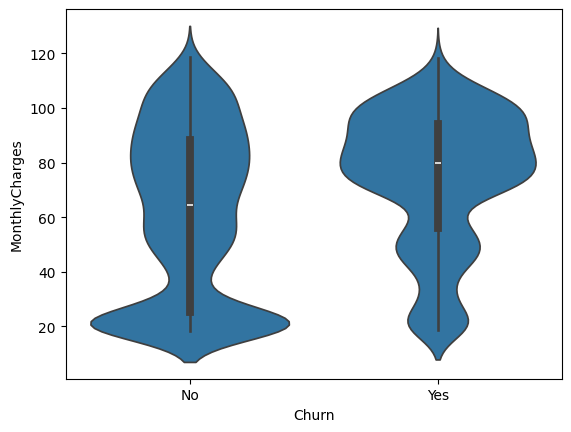

In [64]:
sns.violinplot(data=df_telco, x="Churn", y="MonthlyCharges")

<Axes: xlabel='tenure', ylabel='Count'>

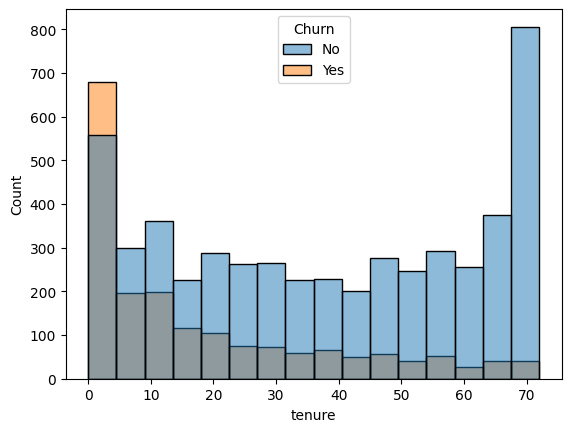

In [67]:
sns.histplot(data=df_telco, x="tenure", hue="Churn")

<Axes: xlabel='tenure'>

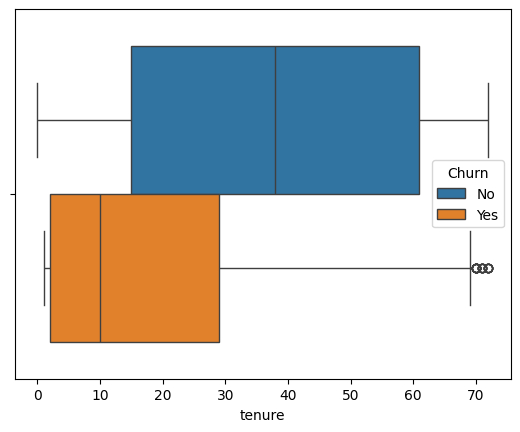

In [68]:
sns.boxplot(data=df_telco, x="tenure", hue="Churn" )

<Axes: xlabel='Churn'>

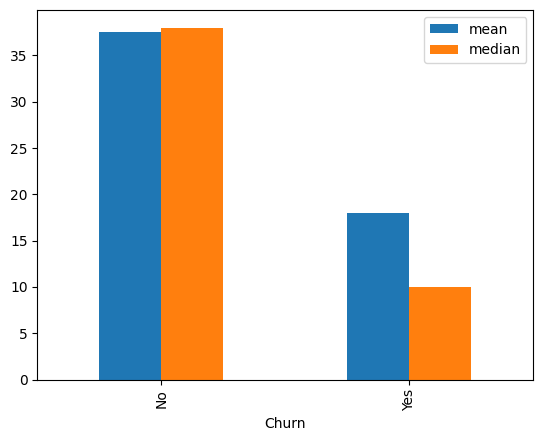

In [70]:
df_telco.groupby("Churn")["tenure"].agg(["mean", "median"]).plot(kind="bar")

In [71]:
df_telco.groupby("Churn")["tenure"].agg(["mean", "median"])

,mean,median
Churn,,
No,37.569965,38.0
Yes,17.979133,10.0


In [76]:
df_telco["tenure_group"] = pd.cut(
    df_telco["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)

df_telco

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,25-48
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25-48
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No,13-24
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No,49-72
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,0-12
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes,0-12


In [87]:
df_telco[df_telco["Churn"]=="Yes"].groupby("tenure_group").size()

tenure_group
0-12     1037
13-24     294
25-48     325
49-72     213
dtype: int64

In [89]:
df_telco["churned"] = df_telco["Churn"]=="Yes"
df_telco.groupby("tenure_group", observed=True)["churned"].mean()*100

tenure_group
0-12     47.438243
13-24    28.710938
25-48    20.388959
49-72     9.513176
Name: churned, dtype: float64

In [ ]:
model = LogisticRegression(class_weight="balanced")  #used when the dataset is not balanced so that the model assigns more weight to the few features
# the goal is to adjust the influence of these few fetures on the loss function, and not to balance the number of exaples

In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

